# Spolehlivost systému

*Nad rámec skripta — aplikace.*

---

Letadlo má tři hydraulické okruhy, server dva zdroje, elektrárna několik nezávislých chladicích smyček. Otázka je pokaždé stejná:

> Jaká je pravděpodobnost, že systém jako celek selže?

U jednoduchých zapojení se to spočítá vzorcem. U složitých se nespočítá vůbec — a simulace je jediná cesta. A když má být systém opravdu spolehlivý, narazíme na starý známý problém: **porucha je tak vzácná, že ji obyčejné Monte Carlo nikdy nevidí**.

Je to táž úloha jako vzácný úpadek pojišťovny v `pojistovna_realisticky`, jen s jinými slovy. A řeší se stejně — **vážením podle důležitosti** ze cvičení 7.

Uvidíte:

- sériové a paralelní zapojení a přesný vzorec jako kontrola
- proč zálohování pomáhá tolik (a kdy ne)
- vzácné poruchy, kde obyčejné MC selže a vážení ne

In [1]:
import math
import random

import matplotlib.pyplot as plt

random.seed(1)  # opakovatelné výsledky


def estimate(xs):
    n = len(xs)
    m = sum(xs) / n
    var = sum((x - m) ** 2 for x in xs) / (n - 1)
    return m, math.sqrt(var / n)


# systém: BLOKU bloků zapojených v sérii, každý blok má V_BLOKU záloh paralelně
BLOKU = 3
V_BLOKU = 2

## 1. Sériově a paralelně

Dvě základní zapojení:

- **Sériové**: systém funguje, jen když fungují **všechny** části. Spolehlivost se násobí, $R = \prod R_i$. Každá další část systém **zhoršuje**.
- **Paralelní** (zálohování): stačí, aby fungovala **aspoň jedna**. Selže, jen když selžou všechny: $R = 1 - \prod (1 - R_i)$. Každá další záloha systém **zlepšuje**.

Náš systém je kombinace: $B$ bloků v sérii, každý blok má $k$ záloh. Blok selže s pravděpodobností $q^k$, a systém selže, když selže aspoň jeden blok:

$$R_{\text{systém}} = \big(1 - q^{k}\big)^{B}.$$

Tenhle vzorec je naše přesná kontrola.

In [2]:
def spolehlivost_presne(q, bloku=BLOKU, v_bloku=V_BLOKU):
    """Pravděpodobnost, že systém funguje."""
    return (1 - q**v_bloku) ** bloku


def porucha_presne(q, **kw):
    return 1 - spolehlivost_presne(q, **kw)


def system_selze(q, bloku=BLOKU, v_bloku=V_BLOKU):
    """Jedna simulace: selže aspoň jeden blok?"""
    for _ in range(bloku):
        if all(random.random() < q for _ in range(v_bloku)):
            return True
    return False


print(f"systém: {BLOKU} bloky v sérii, každý s {V_BLOKU} zálohami\n")
print(f"{'q (komponenta)':>16s} {'simulace':>22s} {'přesně':>12s}")
for q in (0.2, 0.1, 0.05, 0.01):
    M_ = 200_000
    vz = [1.0 if system_selze(q) else 0.0 for _ in range(M_)]
    m, se = estimate(vz)
    print(f"{q:>16.3f} {m:>14.5f} +- {se:.5f} {porucha_presne(q):>12.5f}")
    assert abs(m - porucha_presne(q)) < 5 * se

systém: 3 bloky v sérii, každý s 2 zálohami

  q (komponenta)               simulace       přesně
           0.200        0.11560 +- 0.00071      0.11526


           0.100        0.02926 +- 0.00038      0.02970
           0.050        0.00760 +- 0.00019      0.00748


           0.010        0.00026 +- 0.00004      0.00030


## 2. Kolik zálohování se vyplatí

Zálohování má prudce klesající výnosy — a stojí za to vidět, jak prudce. Blok s $k$ zálohami selže s pravděpodobností $q^k$, takže každá další záloha násobí riziko bloku číslem $q$.

Zároveň ale platí ta nepříjemná strana sériového zapojení: **bloků je víc a stačí, aby selhal jeden.**

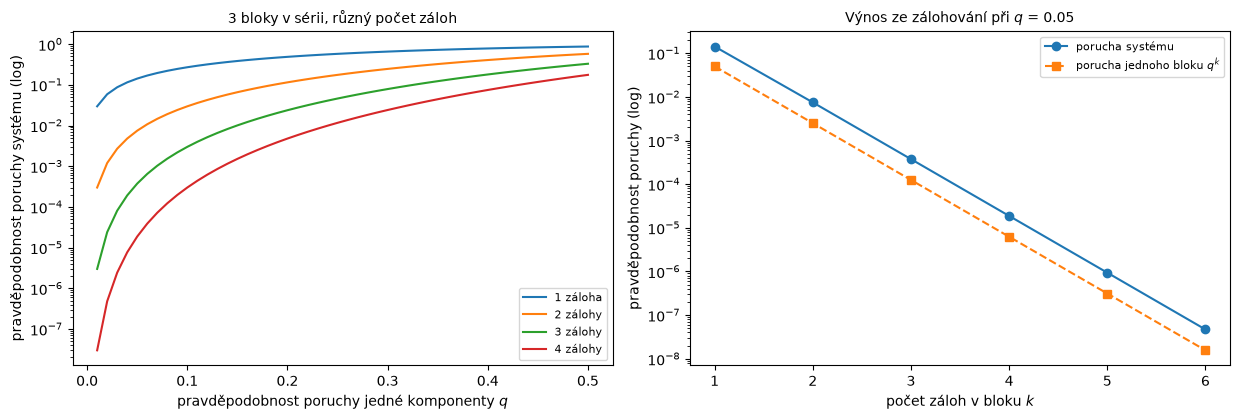

při q = 0.05:
  1 záloh: blok selže s 5.0e-02, systém s 1.4e-01
  2 záloh: blok selže s 2.5e-03, systém s 7.5e-03
  3 záloh: blok selže s 1.3e-04, systém s 3.7e-04
  4 záloh: blok selže s 6.3e-06, systém s 1.9e-05

Systém je zhruba 3krát horší než jeden blok — sériové zapojení
násobí riziko počtem bloků. Zálohovat se vyplatí, ale nejdřív je potřeba
vědět, KTERÝ blok je nejslabší; zálohovat ten už dobrý nepomůže skoro nic.


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))

ax = axes[0]
qq = [0.01 * i for i in range(1, 51)]
for k in (1, 2, 3, 4):
    ax.semilogy(qq, [porucha_presne(q, v_bloku=k) for q in qq], label=f"{k} "
                + ("záloha" if k == 1 else ("zálohy" if k < 5 else "záloh")))
ax.set_xlabel("pravděpodobnost poruchy jedné komponenty $q$")
ax.set_ylabel("pravděpodobnost poruchy systému (log)")
ax.set_title(f"{BLOKU} bloky v sérii, různý počet záloh", fontsize=10)
ax.legend(fontsize=8)

ax = axes[1]
q = 0.05
ks = list(range(1, 7))
ax.semilogy(ks, [porucha_presne(q, v_bloku=k) for k in ks], "o-", label="porucha systému")
ax.semilogy(ks, [q**k for k in ks], "s--", label="porucha jednoho bloku $q^k$")
ax.set_xlabel("počet záloh v bloku $k$")
ax.set_ylabel("pravděpodobnost poruchy (log)")
ax.set_title(f"Výnos ze zálohování při $q$ = {q}", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"při q = {q}:")
for k in (1, 2, 3, 4):
    print(f"  {k} záloh: blok selže s {q**k:.1e}, systém s {porucha_presne(q, v_bloku=k):.1e}")
print(f"\nSystém je zhruba {BLOKU}krát horší než jeden blok — sériové zapojení")
print(f"násobí riziko počtem bloků. Zálohovat se vyplatí, ale nejdřív je potřeba")
print(f"vědět, KTERÝ blok je nejslabší; zálohovat ten už dobrý nepomůže skoro nic.")

## 3. Když je porucha opravdu vzácná

Pro spolehlivé systémy jsou zajímavé hodnoty $q$ kolem $10^{-3}$ a menší. Tam má porucha systému pravděpodobnost kolem $10^{-6}$ a níž — a obyčejné Monte Carlo přestane fungovat, protože z milionu běhů nezaznamená ani jeden.

Řešení je totéž jako u vzácného úpadku pojišťovny: **generujeme s nafouknutou pravděpodobností poruchy $q'$ a vážíme poměrem věrohodností.** Pro každou komponentu zvlášť

$$w = \begin{cases} q/q', & \text{komponenta selhala},\\[1mm] (1-q)/(1-q'), & \text{komponenta funguje},\end{cases}$$

a váha celého běhu je součin přes všechny komponenty.

In [4]:
def porucha_vazenim(q, q_navrh=0.05, M_=50_000):
    """Pravděpodobnost poruchy vážením podle důležitosti."""
    hodnoty = []
    for _ in range(M_):
        w, selhal = 1.0, False
        for _ in range(BLOKU):
            blok = [random.random() < q_navrh for _ in range(V_BLOKU)]
            for komponenta_selhala in blok:
                w *= (q / q_navrh) if komponenta_selhala else ((1 - q) / (1 - q_navrh))
            if all(blok):
                selhal = True
        hodnoty.append(w if selhal else 0.0)
    return estimate(hodnoty)


def porucha_obycejne(q, M_=200_000):
    zasahy = sum(system_selze(q) for _ in range(M_))
    ph = zasahy / M_
    return ph, math.sqrt(max(ph * (1 - ph), 1e-30) / M_), zasahy


print(f"{'q':>8s} {'přesně':>12s} | {'obyčejné MC (200 000)':>28s} | {'vážení (50 000)':>26s}")
qs, chyby_ob, chyby_vz = [], [], []
for q in (1e-2, 1e-3, 1e-4, 1e-5):
    pres = porucha_presne(q)
    ob, se_ob, zasahy = porucha_obycejne(q)
    vz, se_vz = porucha_vazenim(q)
    qs.append(q); chyby_ob.append(se_ob); chyby_vz.append(se_vz)
    print(f"{q:>8.0e} {pres:>12.3e} | {ob:>12.3e} +- {se_ob:>8.1e} ({zasahy:>3d} zásahů) "
          f"| {vz:>12.3e} +- {se_vz:>8.1e}")
    assert abs(vz - pres) < 5 * se_vz, q

print("\nOd q = 1e-3 nenajde obyčejné MC ani jeden zásah a vrátí nulu s nulovou chybou —")
print("tedy sebejisté tvrzení, že systém selhat nemůže. Vážení dává správný řád")
print("a použitelnou chybovou úsečku, a to při ČTVRTINĚ počtu běhů.")

       q       přesně |        obyčejné MC (200 000) |            vážení (50 000)
   1e-02    3.000e-04 |    3.250e-04 +-  4.0e-05 ( 65 zásahů) |    2.922e-04 +-  1.6e-05


   1e-03    3.000e-06 |    0.000e+00 +-  2.2e-18 (  0 zásahů) |    2.790e-06 +-  1.6e-07
   1e-04    3.000e-08 |    0.000e+00 +-  2.2e-18 (  0 zásahů) |    2.888e-08 +-  1.7e-09


   1e-05    3.000e-10 |    0.000e+00 +-  2.2e-18 (  0 zásahů) |    3.369e-10 +-  1.8e-11

Od q = 1e-3 nenajde obyčejné MC ani jeden zásah a vrátí nulu s nulovou chybou —
tedy sebejisté tvrzení, že systém selhat nemůže. Vážení dává správný řád
a použitelnou chybovou úsečku, a to při ČTVRTINĚ počtu běhů.


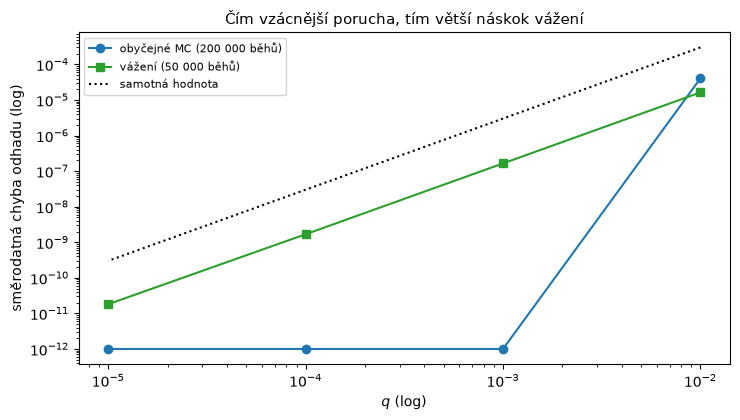

Tečkovaná čára je sama hledaná hodnota. Kde ji křivka chyby přetne,
tam je odhad bezcenný — chyba je větší než výsledek. Obyčejné MC se
tam dostane u q ≈ 1e-3, vážení zůstává o několik řádů níž.


In [5]:
fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.loglog(qs, [max(c, 1e-12) for c in chyby_ob], "o-", label="obyčejné MC (200 000 běhů)")
ax.loglog(qs, chyby_vz, "s-", color="tab:green", label="vážení (50 000 běhů)")
ax.loglog(qs, [porucha_presne(q) for q in qs], "k:", label="samotná hodnota")
ax.set_xlabel("$q$ (log)")
ax.set_ylabel("směrodatná chyba odhadu (log)")
ax.set_title("Čím vzácnější porucha, tím větší náskok vážení", fontsize=11)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print("Tečkovaná čára je sama hledaná hodnota. Kde ji křivka chyby přetne,")
print("tam je odhad bezcenný — chyba je větší než výsledek. Obyčejné MC se")
print("tam dostane u q ≈ 1e-3, vážení zůstává o několik řádů níž.")

## Shrnutí

| Pojem | Co si pamatovat |
|-------|-----------------|
| Sériové zapojení | funguje, jen když **všechno** funguje; $R = \prod R_i$, každá část zhoršuje |
| Paralelní (zálohy) | stačí **jedna**; blok selže s $q^k$, každá záloha násobí riziko $q$ |
| Náš systém | $B$ bloků v sérii po $k$ zálohách ⟹ $R = (1-q^k)^B$ |
| Prudce klesající výnos | zálohovat už spolehlivý blok nemá smysl; najděte nejslabší |
| Vzácné poruchy | obyčejné MC vrátí **nulu s nulovou chybou** — sebejistý nesmysl |
| Vážení | $w = q/q'$ za selhanou a $(1-q)/(1-q')$ za funkční komponentu |
| Kontrola | $q' = q$ vrací obyčejné MC; vzorec $(1-q^k)^B$ hlídá správnost |

Stejná látka jako vzácný úpadek v `pojistovna_realisticky` — jiná slova, tatáž matematika. To je mimochodem dobrý důvod, proč se vyplatí umět metodu, a ne jen úlohu.

### Zkuste si

1. Najděte optimální $q'$ pro $q = 10^{-5}$: zkuste několik hodnot a sledujte směrodatnou chybu. Platí i tady, že optimum je tam, kde se jev stane typickým?
2. Udělejte systém „$k$ z $n$" (funguje, když funguje aspoň $k$ z $n$ komponent). Přesná pravděpodobnost je binomická — ověřte ji.
3. Zaveďte **společnou příčinu**: s pravděpodobností $\varepsilon$ selžou všechny komponenty bloku najednou (výpadek proudu). Jak moc to znehodnotí zálohování?
4. Komponenty ať stárnou: $q$ roste s časem podle Weibullova rozdělení. Spočítejte pravděpodobnost poruchy během roku provozu.
5. Při rozpočtu na jednu zálohu navíc — do kterého bloku ji dát, když mají bloky různá $q$? Ověřte simulací.
6. Porovnejte vážení se **stratifikací** podle počtu selhaných komponent (cvičení 7). Která metoda je tu lepší?